## **Summary**

#### 1. Data selection and preprocessing

#### 2. Clustering experiments and saved results

#### 3. Visualization of some results (need to run 1.)

#### 4. Conclusions

In [1]:
import import_first

from common import (deploy_utils, feature_utils, plot_utils, cluster_utils)

from pathlib import PurePath

import time
import numpy as np
import matplotlib.pyplot as plt

import pickle

## **1. Get data**

In [2]:
trace = deploy_utils.Trace.read_trace(
    file_path=PurePath("..") / ".." / "data" / "6_to_8am.csv")
print("trace summary:\n" + deploy_utils.Trace.summarize_trace(trace=trace))

trace summary:
[+] number of vehicles: 75516
[+] number of lines: 2182717
[+] x interval: [0, 99]
[+] y interval: [0, 99]


In [5]:
v_df = feature_utils.Features.create_basic_vehicle_df(trace=trace)

In [6]:
v_df.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,280,16,0.057143,3.166598,3.896292
1,660,35,0.053030,9.093438,4.847520
2,400,27,0.067500,6.107182,4.534184
3,230,14,0.060870,2.945942,3.675311
4,740,41,0.055405,9.749632,5.136696


### 1.1 Preprocessing

In [7]:
v_df, _ = cluster_utils.Preprocessing.do_standard_scale(df=v_df, features=v_df.columns.tolist())

In [8]:
v_df.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,-0.956085,-0.685207,0.686673,-0.692637,-0.222071
1,0.205044,0.323697,0.378576,0.711783,0.675063
2,-0.589413,-0.101105,1.462592,0.004162,0.379546
3,-1.108865,-0.791407,0.965864,-0.744924,-0.430485
4,0.449492,0.642298,0.556510,0.867275,0.947794


## **2. Clustering**

Sample 20% of vehicles

In [9]:
import random
rng = random.Random(x=123)
v_samples = rng.sample(population=v_df.index.tolist(), k=int(len(v_df) * 0.2))

In [10]:
v_df_reduced = v_df.loc[v_samples]

In [11]:
v_df.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,-0.956085,-0.685207,0.686673,-0.692637,-0.222071
1,0.205044,0.323697,0.378576,0.711783,0.675063
2,-0.589413,-0.101105,1.462592,0.004162,0.379546
3,-1.108865,-0.791407,0.965864,-0.744924,-0.430485
4,0.449492,0.642298,0.556510,0.867275,0.947794


In [12]:
v_df_reduced.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
6863,-0.864417,-0.791407,-0.210942,-0.558798,-0.411443
35084,-0.100516,-0.525906,-1.052456,-0.668550,-0.195774
11427,0.449492,0.536098,0.354033,0.699495,0.757937
53377,-0.650525,-0.632106,-0.242740,-0.711505,-0.281942
34937,0.602273,1.385701,1.621434,2.128323,1.348572


In [13]:
# clust_results = cluster_utils.Clustering.evaluate_kmeans_feature_combinations(
#     df=v_df_reduced, feature_columns=["entropy", "radius_of_gyration", "trip_duration"],
#     min_features=2, max_features=3, k_values=[2, 3, 4], n_runs=100)

In [14]:
# with open(PurePath("..") / "saves" / "v_clust_kmeans_results.pkl", "wb") as f:
#     pickle.dump(clust_results, f)

In [3]:
with open(PurePath("..") / "saves" / "v_clust_kmeans_results.pkl", "rb") as f:
    clust_results = pickle.load(f)
    print(len(clust_results))

1200


In [4]:
clust_results.head()

,features,n_features,k,run,silhouette,calinski_harabasz,davies_bouldin,inertia
0,"(entropy, radius_of_gyration)",2,2,0,0.543640,23997.208329,0.638564,11764.023059
1,"(entropy, radius_of_gyration)",2,2,1,0.542963,23998.101905,0.639812,11763.537133
2,"(entropy, radius_of_gyration)",2,2,2,0.542963,23998.101905,0.639812,11763.537133
3,"(entropy, radius_of_gyration)",2,2,3,0.542963,23998.101905,0.639812,11763.546749
4,"(entropy, radius_of_gyration)",2,2,4,0.543640,23997.208329,0.638564,11764.023059


In [5]:
clust_results_summary = (
    clust_results
    .groupby(["features", "k"])
    .agg(
        silhouette_mean=("silhouette", "mean"),
        silhouette_std=("silhouette", "std"),

        calinski_harabasz_mean=(
            "calinski_harabasz", "mean"
        ),
        calinski_harabasz_std=(
            "calinski_harabasz", "std"
        ),

        davies_bouldin_mean=(
            "davies_bouldin", "mean"
        ),
        davies_bouldin_std=(
            "davies_bouldin", "std"
        ),

        inertia_mean=("inertia", "mean"),
        inertia_std=("inertia", "std"),
    )
    .reset_index()
)

In [6]:
clust_results_summary.head()

,features,k,silhouette_mean,silhouette_std,calinski_harabasz_mean,calinski_harabasz_std,davies_bouldin_mean,davies_bouldin_std,inertia_mean,inertia_std
0,"(entropy, radius_of_gyration)",2,0.543204,0.000319,23997.830690,0.294636,0.639370,0.000585,11763.687437,0.155884
1,"(entropy, radius_of_gyration)",3,0.492822,0.000181,27238.923662,7.315093,0.627482,0.000618,6610.331465,1.462915
2,"(entropy, radius_of_gyration)",4,0.483674,0.000615,30589.207001,8.408008,0.619837,0.000383,4303.539524,1.096529
3,"(entropy, radius_of_gyration, trip_duration)",2,0.511320,0.000357,21175.257283,0.197213,0.705455,0.000388,18783.314307,0.145670
4,"(entropy, radius_of_gyration, trip_duration)",3,0.432820,0.000046,20706.637534,0.977737,0.741924,0.001029,12056.363667,0.485874


In [7]:
clust_results_summary.sort_values(by=["silhouette_mean", "calinski_harabasz_mean", "davies_bouldin_mean", "inertia_mean"], ascending=[False, False, True, True], inplace=True)

In [87]:
print(f"{'features':<50}\t\t\tK\t" "Silhouette ↑\t\tC-H ↑\t\t\t\tDavies ↓\t\tInertia ↓")

for _, row in clust_results_summary.iterrows():

    if row["k"] != 3:
        continue

    print(
        f"{str(row['features']):<50}\t\t\t"
        f"{int(row['k'])}\t"
        f"{row['silhouette_mean']:.3f} ± "
        f"{row['silhouette_std']:.2f}\t\t"
        f"{row['calinski_harabasz_mean']:.2f} ± "
        f"{row['calinski_harabasz_std']:.2f}\t\t\t"
        f"{row['davies_bouldin_mean']:.3f} ± "
        f"{row['davies_bouldin_std']:.3f}\t\t"
        f"{row["inertia_mean"]}"
    )

features                                          			K	Silhouette ↑		C-H ↑				Davies ↓		Inertia ↓
('entropy', 'radius_of_gyration')                 			3	0.493 ± 0.00		27238.92 ± 7.32			0.627 ± 0.001		6610.3314652489835
('radius_of_gyration', 'trip_duration')           			3	0.470 ± 0.00		23778.60 ± 2.31			0.740 ± 0.002		7210.429817442187
('entropy', 'trip_duration')                      			3	0.438 ± 0.00		19765.23 ± 1.75			0.730 ± 0.002		8255.471889937038
('entropy', 'radius_of_gyration', 'trip_duration')			3	0.433 ± 0.00		20706.64 ± 0.98			0.742 ± 0.001		12056.363666698855


## **3. Visualization**

***1. Picking, for each number of features, the best \<feature combination\> and \<K value\> (considering all metrics).***

***2. Then running kmeans 30 times to select the best run on silhouette score.***

***3. Lastly, visualizing the results***

In [59]:
print(trace["vehicle_id"].nunique())
trace.head()

75516


,vehicle_id,time_instant,x,y,cell_dwell_time
0,0,24180,60,50,10
1,0,24190,60,49,20
2,0,24210,60,48,10
3,0,24220,60,47,30
4,0,24250,59,46,20


In [55]:
trace_reduced = trace[trace["vehicle_id"].isin(v_samples)]

In [58]:
print(trace_reduced["vehicle_id"].nunique())
trace_reduced.head()

15103


,vehicle_id,time_instant,x,y,cell_dwell_time
92,4,23770,38,77,20
93,4,23790,37,77,20
94,4,23810,38,77,10
95,4,23820,39,76,20
96,4,23840,40,75,20


In [79]:
from matplotlib.legend_handler import HandlerLine2D
from matplotlib.lines import Line2D

def run_and_visualize(features, k):

    clust_res, _, score, _ = cluster_utils.Clustering.run_kmeans(
        df=v_df_reduced, features=features, k=k, n_runs=30)
    print(score)
    print(clust_res["cluster"].value_counts())

    plot_utils.Plot.plot_trajectories_by_cluster(
        trace=trace_reduced, clusters=clust_res.reset_index(names="vehicle_id"),
        figsize=(7, 7), alpha=0.1)

    # Copy the original properties (color, style, etc.) first, THEN overwrite the linewidth
    plt.legend(handler_map={
        Line2D: HandlerLine2D(update_func=lambda prop, obj: (prop.update_from(obj), prop.set_linewidth(6)))
    })

    plt.show()

0.4328838247236027
cluster
2    6366
1    5099
0    3638
Name: count, dtype: int64


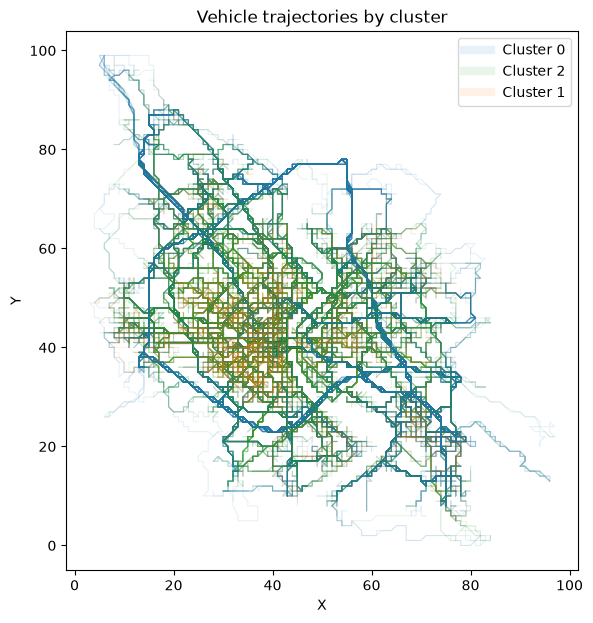

In [81]:
run_and_visualize(
    features=["entropy", "radius_of_gyration", "trip_duration"], k=3)

0.4930066615525234
cluster
2    6868
1    4626
0    3609
Name: count, dtype: int64


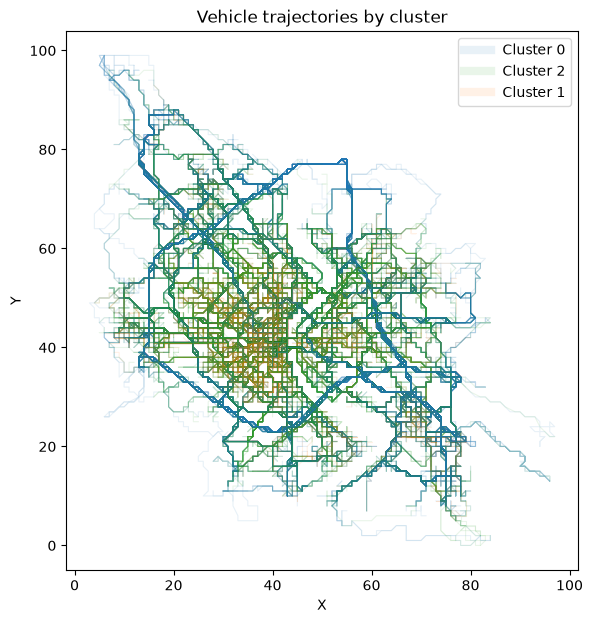

In [84]:
run_and_visualize(
    features=["entropy", "radius_of_gyration"], k=3)

0.4719274587655174
cluster
2    6984
1    5436
0    2683
Name: count, dtype: int64


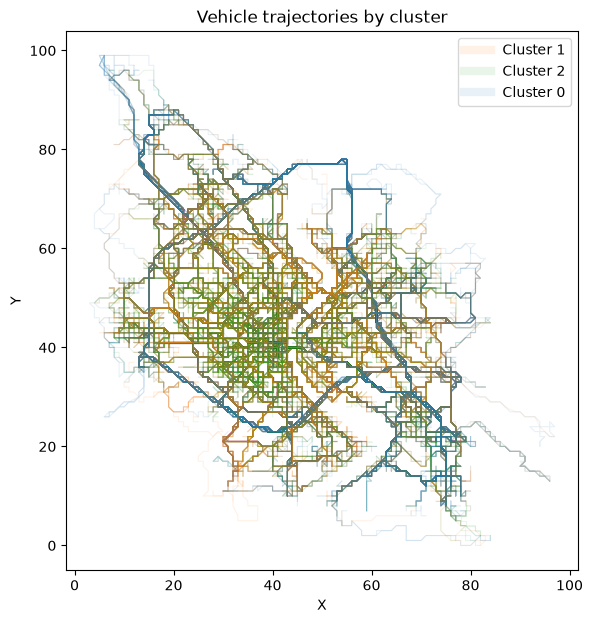

In [85]:
run_and_visualize(
    features=["trip_duration", "radius_of_gyration"], k=3)

0.43909350599643426
cluster
2    6740
1    4574
0    3789
Name: count, dtype: int64


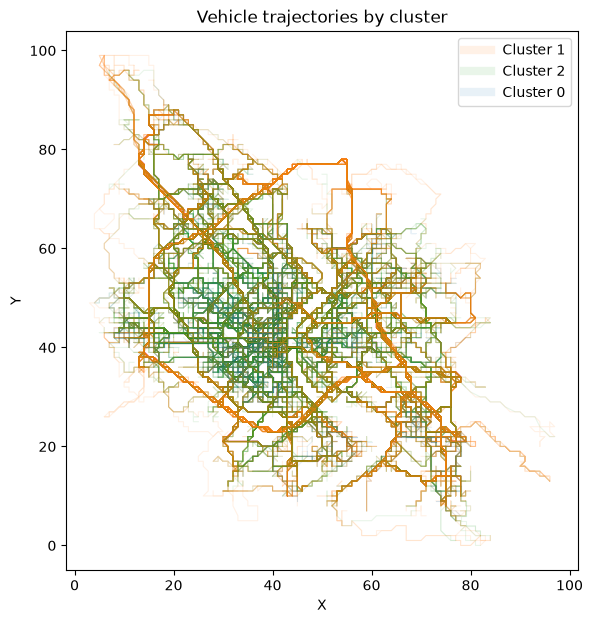

In [86]:
run_and_visualize(
    features=["entropy", "trip_duration"], k=3)

## **4. Conclusions**

- Many results, that aparently look similar
- Maybe stick to the three features (see v_clust_kmeans_iterp.ipynb), and k = 3